# 08 — Candidate-call segmentation

## Objective

The statistical detector is now frozen. This notebook isolates the **front-end segmentation problem**
before any pond / field presence-absence experiment is run.

The goal is:

> **long labelled Dataset-1 WAV → candidate acoustic intervals**

and to compare those intervals against the manual call endpoints already present in the `.mat`
annotation files.

This notebook deliberately does **not**:

- load Dataset 2 / pond recordings;
- classify candidate intervals with the final GMMs;
- apply LLR thresholds;
- estimate presence/absence.

That separation matters. If segmentation and classification are tuned together on field audio, it
becomes very easy to make the whole system look better without knowing which component actually
improved. Apparently even frogs deserve clean ablation studies.

---

## What comes from the paper

`[PAPER]`

The front end described in Sections 3.2–3.3 uses:

1. consecutive **30 s** audio blocks;
2. a species-specific **band-pass FIR** filter;
3. frequency limits chosen from the species call ranges;
4. **10 ms non-overlapping** short-time-energy (STE) frames;
5. a moving-average filter with **MA = 12**;
6. **3 consecutive values above threshold** to start a segment;
7. **3 consecutive values below threshold** to end it.

The paper states that the frequency-domain filter is used for segmentation. The corresponding interval
from the **original unfiltered signal** is what later undergoes feature extraction and classification.

The paper prints the endpoint quantity

\[
\zeta_{dB}
=
\frac{
\max(STE_{dB})-\operatorname{mean}(STE_{dB})
}{C},
\]

where `C` is empirically determined.

### Unresolved detail

With conventional absolute dB values, the printed expression is ambiguous as a directly comparable
threshold because it is a positive range while `STE_dB` can be negative. The paper also does not report
the numerical value of `C`.

`[REPLICATION DECISION]`

We therefore keep the same practical interpretation used in the earlier prototype:

\[
threshold_{dB}
=
\operatorname{mean}(STE_{dB})
+
\frac{
\max(STE_{dB})-\operatorname{mean}(STE_{dB})
}{C}.
\]

Crucially, **we no longer guess `C = 2` and immediately scan field audio**.

Instead, this notebook uses Dataset 1's manual call intervals to measure segmentation behavior across a
grid of `C` values. The final field recordings remain untouched at this stage.

---

## Validation philosophy

The annotations provide target call intervals for each species. They are suitable for measuring whether
the front end captures known calls.

However, a candidate interval that does not overlap a target annotation is **not automatically a
biological false positive**. It might contain another animal, another frog species, noise, or an
unannotated acoustic event.

Therefore we emphasize:

- **call recall**;
- fraction of each annotated call covered by candidate intervals;
- total candidate duration relative to annotated duration;
- candidate count.

We avoid pretending that candidate-level "precision" against these annotations is equivalent to the
final detector precision.

In [1]:
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from scipy.io import loadmat
from scipy.signal import fftconvolve, firwin

try:
    from dotenv import load_dotenv
except ImportError as exc:
    raise ImportError(
        "Notebook 08 needs python-dotenv to resolve MENDELEY_CALL_DIR."
    ) from exc

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 100)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = (
    REPO_ROOT / "data" / "processed"
)

CALLS_PATH = (
    PROCESSED_DIR / "calls.csv"
)

FINAL_MANIFEST_PATH = (
    REPO_ROOT
    / "models"
    / "gmm_robust_final"
    / "final_detector_manifest.json"
)

RESULTS_DIR = (
    PROCESSED_DIR
    / "candidate_call_segmentation"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for path in (
    CALLS_PATH,
    FINAL_MANIFEST_PATH,
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required input: {path}"
        )

load_dotenv(
    REPO_ROOT / ".env"
)

mendeley_value = os.environ.get(
    "MENDELEY_CALL_DIR"
)

if not mendeley_value:
    raise RuntimeError(
        "MENDELEY_CALL_DIR is not defined in .env."
    )

MENDELEY_CALL_DIR = Path(
    mendeley_value
).expanduser()

if not MENDELEY_CALL_DIR.is_dir():
    raise FileNotFoundError(
        f"MENDELEY_CALL_DIR does not exist: {MENDELEY_CALL_DIR}"
    )

print("Repository root :", REPO_ROOT)
print("Dataset         : Dataset 1 / labelled Mendeley calls")
print("Dataset folder  :", MENDELEY_CALL_DIR)
print("Results         :", RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Dataset         : Dataset 1 / labelled Mendeley calls
Dataset folder  : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data
Results         : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\candidate_call_segmentation


## 2. Load final detector class set

The models are not used here, but the final manifest tells us exactly which species the deployed system
can represent.

`f09` remains excluded because the recovered labelled material was insufficient to build a deployable
model.

In [2]:
with open(
    FINAL_MANIFEST_PATH,
    "r",
    encoding="utf-8",
) as f:
    FINAL_MANIFEST = json.load(f)

USABLE_CODES = tuple(
    FINAL_MANIFEST[
        "classes"
    ]
)

print(
    "Frozen detector classes:",
    USABLE_CODES,
)

print(
    "Frozen detector feature:",
    FINAL_MANIFEST[
        "feature"
    ],
)

print(
    "Frozen detector M:",
    FINAL_MANIFEST[
        "n_components"
    ],
)

Frozen detector classes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')
Frozen detector feature: 20_PLP_RASTA
Frozen detector M: 4


## 3. Reconstruct the exact Dataset-1 call endpoints

Notebook 02 intentionally kept `calls.csv` compact and did not persist `start`/`end`.

As in notebook 05's feature-comparison reconstruction, we read the same `.mat` files, reproduce the
annotation order, and verify row-by-row alignment before attaching endpoints **in memory only**.

Notebook 02 and `calls.csv` are not modified.

In [3]:
calls = (
    pd.read_csv(
        CALLS_PATH
    )
    .copy()
    .reset_index(drop=True)
)

required_columns = {
    "code",
    "species",
    "wav",
    "recording",
    "rate",
    "seconds",
    "frames",
}

missing = (
    required_columns
    - set(calls.columns)
)

if missing:
    raise ValueError(
        f"calls.csv is missing required columns: {sorted(missing)}"
    )

calls["call_id"] = [
    f"call_{i:04d}"
    for i in range(
        len(calls)
    )
]

SEGMENT_DIR = (
    MENDELEY_CALL_DIR
    / "segment files"
)

if not SEGMENT_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find the segment-files directory: {SEGMENT_DIR}"
    )

PAPER_TABLE1 = pd.DataFrame(
    [
        (
            "f01",
            "Boana alfaroi",
            "cantos_alfaroi.mat",
            1660,
            3100,
        ),
        (
            "f02",
            "Dendropsophus bifurcus",
            "cantos_bifurcus.mat",
            2300,
            3390,
        ),
        (
            "f03",
            "Boana cinerascens",
            "cantos_cinerascens.mat",
            1300,
            1530,
        ),
        (
            "f04",
            "Pristimantis conspicillatus",
            "cantos_conspicillatus.mat",
            1630,
            3900,
        ),
        (
            "f05",
            "Leptodactylus discodactylus",
            "cantos_discodactylus.mat",
            1680,
            3260,
        ),
        (
            "f06",
            "Osteocephalus fuscifacies",
            "cantos_fuscifacies.mat",
            1000,
            2500,
        ),
        (
            "f07",
            "Boana lanciformis",
            "cantos_lanciformis.mat",
            500,
            2720,
        ),
        (
            "f08",
            "Rhinella margaritifera",
            "cantos_margaritifer.mat",
            800,
            1700,
        ),
        (
            "f09",
            "Dendropsophus parviceps",
            "cantos_parviceps.mat",
            5660,
            7500,
        ),
        (
            "f10",
            "Engystomops petersi",
            "cantos_petersi.mat",
            430,
            3140,
        ),
    ],
    columns=[
        "code",
        "species",
        "segment_file",
        "low_hz",
        "high_hz",
    ],
)

WAV_ON_DISK = {
    path.name.lower(): path
    for path
    in MENDELEY_CALL_DIR.rglob("*")
    if path.suffix.lower() == ".wav"
}


def read_calls_from_segment_file(
    filename,
):
    rows = []

    mat = loadmat(
        SEGMENT_DIR / filename
    )

    if "cantos" not in mat:
        raise KeyError(
            f"{filename} does not contain 'cantos'."
        )

    for position, (
        path,
        intervals,
        rate,
    ) in enumerate(
        mat["cantos"]
    ):
        wav = Path(
            str(
                path[0]
            ).replace(
                "\\",
                "/",
            )
        ).name

        for start, end in intervals:
            rows.append({
                "segment_file":
                    filename,
                "recording":
                    position,
                "wav":
                    wav,
                "rate":
                    int(
                        rate[0][0]
                    ),
                "start":
                    int(start),
                "end":
                    int(end),
            })

    return pd.DataFrame(
        rows
    )


annotated = pd.concat(
    [
        read_calls_from_segment_file(
            filename
        )
        for filename
        in PAPER_TABLE1[
            "segment_file"
        ]
    ],
    ignore_index=True,
)

annotated = annotated.merge(
    PAPER_TABLE1[
        [
            "code",
            "species",
            "segment_file",
        ]
    ],
    on="segment_file",
)

annotated["seconds"] = (
    annotated["end"]
    - annotated["start"]
) / annotated["rate"]

annotated["on_disk"] = (
    annotated["wav"]
    .str.lower()
    .isin(
        WAV_ON_DISK
    )
)

available_annotations = (
    annotated[
        annotated[
            "on_disk"
        ]
    ]
    .reset_index(drop=True)
)

print(
    "Segment-file calls        :",
    len(annotated),
)

print(
    "Calls whose WAV is present:",
    len(
        available_annotations
    ),
)

print(
    "Rows in calls.csv         :",
    len(calls),
)

if len(
    available_annotations
) != len(calls):
    raise RuntimeError(
        "Reconstructed annotations and calls.csv have different row counts."
    )

Segment-file calls        : 1510
Calls whose WAV is present: 1461
Rows in calls.csv         : 1461


In [4]:
alignment = pd.DataFrame({
    "code_match":
        calls[
            "code"
        ].astype(str).to_numpy()
        == available_annotations[
            "code"
        ].astype(str).to_numpy(),

    "species_match":
        calls[
            "species"
        ].astype(str).to_numpy()
        == available_annotations[
            "species"
        ].astype(str).to_numpy(),

    "wav_match":
        calls[
            "wav"
        ].astype(str).str.lower().to_numpy()
        == available_annotations[
            "wav"
        ].astype(str).str.lower().to_numpy(),

    "recording_match":
        calls[
            "recording"
        ].astype(int).to_numpy()
        == available_annotations[
            "recording"
        ].astype(int).to_numpy(),

    "rate_match":
        calls[
            "rate"
        ].astype(int).to_numpy()
        == available_annotations[
            "rate"
        ].astype(int).to_numpy(),

    "seconds_match":
        np.isclose(
            calls[
                "seconds"
            ].astype(float).to_numpy(),
            available_annotations[
                "seconds"
            ].astype(float).to_numpy(),
            atol=1e-10,
            rtol=1e-10,
        ),
})

display(
    alignment
    .mean()
    .rename(
        "share_matching"
    )
    .to_frame()
)

if not alignment.to_numpy().all():

    bad_rows = np.where(
        ~alignment
        .all(axis=1)
        .to_numpy()
    )[0]

    raise RuntimeError(
        f"Annotation alignment failed for {len(bad_rows)} rows."
    )

calls["start"] = (
    available_annotations[
        "start"
    ]
    .astype(int)
    .to_numpy()
)

calls["end"] = (
    available_annotations[
        "end"
    ]
    .astype(int)
    .to_numpy()
)

calls["resolved_wav"] = [
    str(
        WAV_ON_DISK[
            wav.lower()
        ]
    )
    for wav
    in calls[
        "wav"
    ]
]

calls["recording_group"] = (
    calls[
        "wav"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

CALLS_BY_ID = (
    calls.set_index(
        "call_id",
        drop=False,
    )
)

print(
    "Annotation alignment: 100%"
)

print(
    "calls.csv modified on disk: NO"
)

,share_matching
code_match,1.0
species_match,1.0
wav_match,1.0
recording_match,1.0
rate_match,1.0
seconds_match,1.0


Annotation alignment: 100%
calls.csv modified on disk: NO


## 4. Dataset-1 recording inventory for segmentation

Only the final nine deployable classes are evaluated.

In [5]:
usable_calls = (
    calls[
        calls[
            "code"
        ].isin(
            USABLE_CODES
        )
    ]
    .copy()
    .reset_index(drop=True)
)

recording_inventory = (
    usable_calls
    .groupby(
        [
            "code",
            "species",
            "recording_group",
            "resolved_wav",
        ],
        as_index=False,
    )
    .agg(
        n_calls=(
            "call_id",
            "size",
        ),
        annotated_seconds=(
            "seconds",
            "sum",
        ),
        sample_rate=(
            "rate",
            "first",
        ),
    )
)

species_inventory = (
    recording_inventory
    .groupby(
        [
            "code",
            "species",
        ],
        as_index=False,
    )
    .agg(
        n_recordings=(
            "recording_group",
            "nunique",
        ),
        n_calls=(
            "n_calls",
            "sum",
        ),
        annotated_seconds=(
            "annotated_seconds",
            "sum",
        ),
    )
)

display(
    species_inventory.round(3)
)

,code,species,n_recordings,n_calls,annotated_seconds
0,f01,Boana alfaroi,5,98,44.72
1,f02,Dendropsophus bifurcus,10,99,41.72
2,f03,Boana cinerascens,8,169,102.58
3,f04,Pristimantis conspicillatus,9,186,77.94
4,f05,Leptodactylus discodactylus,3,340,114.36
5,f06,Osteocephalus fuscifacies,5,54,24.94
6,f07,Boana lanciformis,7,101,57.84
7,f08,Rhinella margaritifera,7,96,102.66
8,f10,Engystomops petersi,12,316,134.00


## 5. Species-specific frequency bands

These intervals are the frequency ranges reported in Table 1 of the paper.

The FIR output is used **only to estimate candidate endpoints**.

In [6]:
PAPER_FREQUENCY_BANDS_HZ = {
    row.code: (
        float(
            row.low_hz
        ),
        float(
            row.high_hz
        ),
    )
    for row
    in PAPER_TABLE1.itertuples(
        index=False
    )
}

SEGMENTATION_BANDS_HZ = {
    code:
        PAPER_FREQUENCY_BANDS_HZ[
            code
        ]
    for code
    in USABLE_CODES
}

band_table = pd.DataFrame([
    {
        "code":
            code,
        "low_hz":
            band[0],
        "high_hz":
            band[1],
    }
    for code, band
    in SEGMENTATION_BANDS_HZ.items()
])

display(
    band_table
)

,code,low_hz,high_hz
0,f01,1660.0,3100.0
1,f02,2300.0,3390.0
2,f03,1300.0,1530.0
3,f04,1630.0,3900.0
4,f05,1680.0,3260.0
5,f06,1000.0,2500.0
6,f07,500.0,2720.0
7,f08,800.0,1700.0
8,f10,430.0,3140.0


## 6. Front-end configuration and `C` grid

### Paper-specified values

- block: `30 s`
- STE frame: `10 ms`
- overlap: `0%`
- moving average: `12`
- endpoint persistence: `3`

### Reconstruction choices

The paper does not report the FIR order or the empirical `C`.

We retain the earlier **513-tap linear-phase FIR** choice and evaluate a broad grid of `C`.

Because the practical threshold is

\[
mean + 
rac{max-mean}{C},
\]

larger `C` values make the detector **more sensitive** by moving the threshold closer to the mean.

In [7]:
BLOCK_SECONDS = 30.0

STE_FRAME_SECONDS = 0.010
STE_MA_LENGTH = 12
ENDPOINT_RUN = 3

FIR_NUMTAPS = 513

C_GRID = (
    1.25,
    1.50,
    1.75,
    2.00,
    2.50,
    3.00,
    4.00,
    5.00,
    6.00,
    8.00,
    10.00,
)

# A known call is counted as robustly captured when candidate intervals
# cover at least this fraction of its annotated duration.
CALL_COVERAGE_TARGET = 0.50

# Segmentation should favor recall: anything missed here can never reach
# the classifier. Among C values reaching this recall target, we minimize
# candidate burden.
TARGET_CALL_RECALL = 0.95

RECOMPUTE_GRID = True

GRID_RESULTS_PATH = (
    RESULTS_DIR
    / "segmentation_grid_metrics.csv"
)

print(
    "C grid:",
    C_GRID,
)

C grid: (1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0)


## 7. FIR filtering, STE, moving average and endpoint logic

The implementation intentionally mirrors the earlier paper-prototype front end, but now its behavior is
measured against known Dataset-1 endpoints.

In [8]:
def to_mono(
    audio,
):
    audio = np.asarray(
        audio,
        dtype=np.float64,
    )

    if audio.ndim == 1:
        return audio

    if audio.ndim == 2:
        return audio.mean(
            axis=1
        )

    raise ValueError(
        f"Unsupported audio shape: {audio.shape}"
    )


def bandpass_for_segmentation(
    audio,
    sr,
    low_hz,
    high_hz,
    numtaps=FIR_NUMTAPS,
):
    audio = np.asarray(
        audio,
        dtype=np.float64,
    )

    nyquist = sr / 2.0

    if not (
        0
        < low_hz
        < high_hz
        < nyquist
    ):
        raise ValueError(
            f"Invalid band ({low_hz}, {high_hz}) for sr={sr}."
        )

    taps = firwin(
        numtaps=numtaps,
        cutoff=[
            low_hz,
            high_hz,
        ],
        pass_zero=False,
        fs=sr,
    )

    return fftconvolve(
        audio,
        taps,
        mode="same",
    )


def short_time_energy(
    audio,
    sr,
    frame_seconds=STE_FRAME_SECONDS,
):
    frame_samples = int(
        round(
            sr
            * frame_seconds
        )
    )

    if frame_samples <= 0:
        raise ValueError(
            "STE frame size must be positive."
        )

    n_frames = (
        len(audio)
        // frame_samples
    )

    if n_frames == 0:
        return (
            np.empty(
                0,
                dtype=float,
            ),
            frame_samples,
        )

    trimmed = audio[
        :
        n_frames
        * frame_samples
    ]

    frames = trimmed.reshape(
        n_frames,
        frame_samples,
    )

    energy = np.sum(
        frames
        * frames,
        axis=1,
    )

    return (
        energy,
        frame_samples,
    )


def moving_average_same(
    values,
    length=STE_MA_LENGTH,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    if len(values) == 0:
        return values.copy()

    kernel = (
        np.ones(
            length,
            dtype=float,
        )
        / length
    )

    return np.convolve(
        values,
        kernel,
        mode="same",
    )


def energy_to_db(
    energy,
):
    energy = np.asarray(
        energy,
        dtype=float,
    )

    floor = np.finfo(
        float
    ).tiny

    return (
        10.0
        * np.log10(
            np.maximum(
                energy,
                floor,
            )
        )
    )


def endpoint_threshold_db(
    ste_db,
    C,
):
    ste_db = np.asarray(
        ste_db,
        dtype=float,
    )

    if C <= 0:
        raise ValueError(
            "C must be positive."
        )

    if len(ste_db) == 0:
        return np.nan

    mean_db = float(
        np.mean(
            ste_db
        )
    )

    max_db = float(
        np.max(
            ste_db
        )
    )

    return (
        mean_db
        + (
            max_db
            - mean_db
        )
        / C
    )


def find_endpoint_runs(
    ste_db,
    threshold_db,
    run_length=ENDPOINT_RUN,
):
    ste_db = np.asarray(
        ste_db,
        dtype=float,
    )

    if len(ste_db) == 0:
        return []

    segments = []

    in_segment = False
    start_idx = None

    i = 0

    while (
        i
        <= len(ste_db)
        - run_length
    ):

        if not in_segment:

            if np.all(
                ste_db[
                    i:
                    i + run_length
                ]
                > threshold_db
            ):
                start_idx = i
                in_segment = True

                i += run_length
                continue

        else:

            if np.all(
                ste_db[
                    i:
                    i + run_length
                ]
                < threshold_db
            ):
                end_idx = i

                if (
                    start_idx
                    is not None
                    and end_idx
                    > start_idx
                ):
                    segments.append(
                        (
                            start_idx,
                            end_idx,
                        )
                    )

                start_idx = None
                in_segment = False

                i += run_length
                continue

        i += 1

    if (
        in_segment
        and start_idx
        is not None
    ):
        segments.append(
            (
                start_idx,
                len(
                    ste_db
                ),
            )
        )

    return segments

## 8. Prepare a recording once, then test many `C` values

Filtering and STE do not depend on `C`, so they are computed once per:

`species × WAV × 30-second block`.

Only the final threshold and endpoint logic are repeated over the grid.

In [9]:
def read_full_wav(
    wav_path,
):
    audio, sr = sf.read(
        wav_path,
        always_2d=False,
        dtype="float64",
    )

    audio = to_mono(
        audio
    )

    return (
        audio,
        int(sr),
    )


def prepare_recording_frontend(
    wav_path,
    code,
):
    wav_path = Path(
        wav_path
    )

    audio, sr = read_full_wav(
        wav_path
    )

    low_hz, high_hz = (
        SEGMENTATION_BANDS_HZ[
            code
        ]
    )

    block_samples = int(
        round(
            BLOCK_SECONDS
            * sr
        )
    )

    blocks = []

    for block_start in range(
        0,
        len(audio),
        block_samples,
    ):
        block_end = min(
            len(audio),
            block_start
            + block_samples,
        )

        original_block = audio[
            block_start:
            block_end
        ]

        filtered = (
            bandpass_for_segmentation(
                original_block,
                sr,
                low_hz,
                high_hz,
            )
        )

        ste, frame_samples = (
            short_time_energy(
                filtered,
                sr,
            )
        )

        ste_smooth = (
            moving_average_same(
                ste,
                STE_MA_LENGTH,
            )
        )

        ste_db = energy_to_db(
            ste_smooth
        )

        blocks.append({
            "block_start_sample":
                block_start,
            "block_end_sample":
                block_end,
            "frame_samples":
                frame_samples,
            "ste_db":
                ste_db,
        })

    return {
        "wav_path":
            str(wav_path),
        "code":
            code,
        "sr":
            sr,
        "n_samples":
            len(audio),
        "duration_seconds":
            len(audio) / sr,
        "blocks":
            blocks,
    }


def candidates_from_prepared(
    prepared,
    C,
):
    rows = []

    sr = int(
        prepared[
            "sr"
        ]
    )

    for block_index, block in enumerate(
        prepared[
            "blocks"
        ]
    ):
        ste_db = block[
            "ste_db"
        ]

        if len(
            ste_db
        ) == 0:
            continue

        threshold_db = (
            endpoint_threshold_db(
                ste_db,
                C=C,
            )
        )

        endpoint_frames = (
            find_endpoint_runs(
                ste_db,
                threshold_db,
            )
        )

        frame_samples = int(
            block[
                "frame_samples"
            ]
        )

        block_start = int(
            block[
                "block_start_sample"
            ]
        )

        block_end = int(
            block[
                "block_end_sample"
            ]
        )

        for (
            start_frame,
            end_frame,
        ) in endpoint_frames:

            start_sample = (
                block_start
                + start_frame
                * frame_samples
            )

            end_sample = min(
                block_end,
                block_start
                + end_frame
                * frame_samples,
            )

            if end_sample <= start_sample:
                continue

            rows.append({
                "code":
                    prepared[
                        "code"
                    ],
                "wav_path":
                    prepared[
                        "wav_path"
                    ],
                "block_index":
                    block_index,
                "C":
                    float(C),
                "threshold_db":
                    float(
                        threshold_db
                    ),
                "start_sample":
                    int(
                        start_sample
                    ),
                "end_sample":
                    int(
                        end_sample
                    ),
                "start_seconds":
                    start_sample
                    / sr,
                "end_seconds":
                    end_sample
                    / sr,
                "duration_seconds":
                    (
                        end_sample
                        - start_sample
                    )
                    / sr,
            })

    return pd.DataFrame(
        rows
    )

## 9. Interval-overlap evaluation

For every known call we calculate the fraction of its annotated duration covered by the union of
candidate intervals.

A call is considered **robustly captured** when at least 50% of its duration is covered.

We also report:

- any-overlap recall;
- 50%-coverage recall;
- total annotation coverage;
- total candidate duration / annotated duration;
- fraction of candidate duration overlapping the target annotations.

The last quantity is an **overlap diagnostic**, not biological precision.

In [10]:
def interval_overlap(
    a_start,
    a_end,
    b_start,
    b_end,
):
    return max(
        0,
        min(
            a_end,
            b_end,
        )
        - max(
            a_start,
            b_start,
        ),
    )


def merge_intervals(
    intervals,
):
    intervals = sorted(
        (
            int(start),
            int(end),
        )
        for start, end
        in intervals
        if end > start
    )

    if not intervals:
        return []

    merged = [
        list(
            intervals[0]
        )
    ]

    for start, end in intervals[
        1:
    ]:
        previous = merged[
            -1
        ]

        if start <= previous[1]:
            previous[1] = max(
                previous[1],
                end,
            )
        else:
            merged.append(
                [
                    start,
                    end,
                ]
            )

    return [
        (
            start,
            end,
        )
        for start, end
        in merged
    ]


def covered_length(
    target_start,
    target_end,
    intervals,
):
    pieces = []

    for start, end in intervals:

        overlap_start = max(
            target_start,
            start,
        )

        overlap_end = min(
            target_end,
            end,
        )

        if overlap_end > overlap_start:
            pieces.append(
                (
                    overlap_start,
                    overlap_end,
                )
            )

    return sum(
        end - start
        for start, end
        in merge_intervals(
            pieces
        )
    )


def evaluate_candidates(
    ground_truth,
    candidates,
    sr,
):
    gt = ground_truth.copy()

    candidate_intervals = [
        (
            int(row.start_sample),
            int(row.end_sample),
        )
        for row
        in candidates.itertuples(
            index=False
        )
    ]

    merged_candidates = (
        merge_intervals(
            candidate_intervals
        )
    )

    call_rows = []

    for row in gt.itertuples(
        index=False
    ):
        gt_start = int(
            row.start
        )

        gt_end = int(
            row.end
        )

        gt_length = max(
            1,
            gt_end - gt_start,
        )

        overlap_samples = (
            covered_length(
                gt_start,
                gt_end,
                merged_candidates,
            )
        )

        coverage = (
            overlap_samples
            / gt_length
        )

        call_rows.append({
            "call_id":
                row.call_id,
            "code":
                row.code,
            "wav":
                row.wav,
            "coverage":
                coverage,
            "any_overlap":
                coverage > 0,
            "covered_50pct":
                coverage
                >= CALL_COVERAGE_TARGET,
        })

    call_metrics = pd.DataFrame(
        call_rows
    )

    gt_intervals = merge_intervals([
        (
            int(row.start),
            int(row.end),
        )
        for row
        in gt.itertuples(
            index=False
        )
    ])

    total_gt_samples = sum(
        end - start
        for start, end
        in gt_intervals
    )

    total_candidate_samples = sum(
        end - start
        for start, end
        in merged_candidates
    )

    gt_covered_samples = sum(
        covered_length(
            start,
            end,
            merged_candidates,
        )
        for start, end
        in gt_intervals
    )

    candidate_overlap_samples = sum(
        covered_length(
            start,
            end,
            gt_intervals,
        )
        for start, end
        in merged_candidates
    )

    summary = {
        "n_gt_calls":
            len(gt),
        "n_candidates":
            len(candidates),
        "call_recall_any":
            float(
                call_metrics[
                    "any_overlap"
                ].mean()
            )
            if len(
                call_metrics
            )
            else np.nan,
        "call_recall_50":
            float(
                call_metrics[
                    "covered_50pct"
                ].mean()
            )
            if len(
                call_metrics
            )
            else np.nan,
        "median_call_coverage":
            float(
                call_metrics[
                    "coverage"
                ].median()
            )
            if len(
                call_metrics
            )
            else np.nan,
        "annotation_coverage":
            (
                gt_covered_samples
                / total_gt_samples
            )
            if total_gt_samples
            else np.nan,
        "candidate_overlap_share":
            (
                candidate_overlap_samples
                / total_candidate_samples
            )
            if total_candidate_samples
            else np.nan,
        "candidate_seconds":
            total_candidate_samples
            / sr,
        "annotated_seconds_union":
            total_gt_samples
            / sr,
        "candidate_burden_ratio":
            (
                total_candidate_samples
                / total_gt_samples
            )
            if total_gt_samples
            else np.nan,
    }

    return (
        summary,
        call_metrics,
    )

## 10. Grid search on Dataset 1

The expensive band-pass filtering and STE calculation are performed once per species-recording pair.
Each prepared recording is then evaluated over the full `C` grid.

In [11]:
grid_rows = []

if (
    GRID_RESULTS_PATH.exists()
    and not RECOMPUTE_GRID
):
    segmentation_grid = pd.read_csv(
        GRID_RESULTS_PATH
    )

    print(
        "Loaded existing grid:",
        GRID_RESULTS_PATH,
    )

else:

    grouped = list(
        usable_calls.groupby(
            [
                "code",
                "recording_group",
                "resolved_wav",
            ],
            sort=True,
        )
    )

    for group_index, (
        (
            code,
            recording_group,
            resolved_wav,
        ),
        gt_group,
    ) in enumerate(
        grouped,
        start=1,
    ):

        print(
            f"{group_index:>3}/{len(grouped)} | "
            f"{code} | {Path(resolved_wav).name}"
        )

        prepared = (
            prepare_recording_frontend(
                resolved_wav,
                code,
            )
        )

        sr = int(
            prepared[
                "sr"
            ]
        )

        expected_sr = int(
            gt_group[
                "rate"
            ].iloc[0]
        )

        if sr != expected_sr:
            raise RuntimeError(
                f"Sample-rate mismatch for {resolved_wav}: "
                f"WAV={sr}, annotation={expected_sr}"
            )

        for C in C_GRID:

            candidates = (
                candidates_from_prepared(
                    prepared,
                    C=C,
                )
            )

            summary, _ = (
                evaluate_candidates(
                    ground_truth=gt_group,
                    candidates=candidates,
                    sr=sr,
                )
            )

            grid_rows.append({
                "code":
                    code,
                "recording_group":
                    recording_group,
                "wav":
                    Path(
                        resolved_wav
                    ).name,
                "resolved_wav":
                    resolved_wav,
                "C":
                    float(C),
                "recording_seconds":
                    prepared[
                        "duration_seconds"
                    ],
                **summary,
            })

    segmentation_grid = pd.DataFrame(
        grid_rows
    )

    segmentation_grid.to_csv(
        GRID_RESULTS_PATH,
        index=False,
    )

    print(
        "Saved:",
        GRID_RESULTS_PATH,
    )

display(
    segmentation_grid.head().round(4)
)

  1/66 | f01 | 1101.WAV
  2/66 | f01 | 1102.WAV
  3/66 | f01 | 1103.WAV
  4/66 | f01 | 1105.WAV
  5/66 | f01 | 1106.WAV
  6/66 | f02 | D-bifircus-D-parviceps-LS100120.WAV
  7/66 | f02 | D-bifurcus-sc10743.wav
  8/66 | f02 | Dbifurcus2.WAV
  9/66 | f02 | Drhodopeplusbifurcus2_Daniel1.WAV
 10/66 | f02 | LS100120.WAV
 11/66 | f02 | LS100303 D. bifurcus sc38590mono.WAV
 12/66 | f02 | LS100536.WAV
 13/66 | f02 | LS100582.WAV
 14/66 | f02 | LS100584.WAV
 15/66 | f02 | LS100594.WAV
 16/66 | f03 | Hcinerascens.WAV
 17/66 | f03 | Hcinerascens2_Daniel.WAV
 18/66 | f03 | Hcinerascens3.WAV
 19/66 | f03 | LS100305_Daniel1.WAV
 20/66 | f03 | LS100306.WAV
 21/66 | f03 | LS100444 H. cinerascensmono.WAV
 22/66 | f03 | LS100459 sc44991-92.WAV
 23/66 | f03 | LS100732.WAV
 24/66 | f04 | LS100307.WAV
 25/66 | f04 | LS100308- Pristimantis conspicillatus.WAV
 26/66 | f04 | LS100309sc37073.WAV
 27/66 | f04 | LS100313- Pristimantis conspicillatus.WAV
 28/66 | f04 | LS100319Pconspicillatus.wav
 29/66 | f04 | LS

,code,recording_group,wav,resolved_wav,C,recording_seconds,n_gt_calls,n_candidates,call_recall_any,call_recall_50,median_call_coverage,annotation_coverage,candidate_overlap_share,candidate_seconds,annotated_seconds_union,candidate_burden_ratio
0,f01,1101.wav,1101.WAV,C:\Users\sofia\Projects\PUCE\frog-presence-rep...,1.25,186.4719,21,19,0.9048,0.0000,0.3158,0.2957,1.0,2.72,9.2,0.2957
1,f01,1101.wav,1101.WAV,C:\Users\sofia\Projects\PUCE\frog-presence-rep...,1.50,186.4719,21,21,1.0000,0.3333,0.4783,0.4543,1.0,4.18,9.2,0.4543
2,f01,1101.wav,1101.WAV,C:\Users\sofia\Projects\PUCE\frog-presence-rep...,1.75,186.4719,21,21,1.0000,0.8571,0.5217,0.5250,1.0,4.83,9.2,0.5250
3,f01,1101.wav,1101.WAV,C:\Users\sofia\Projects\PUCE\frog-presence-rep...,2.00,186.4719,21,21,1.0000,0.9524,0.5435,0.5467,1.0,5.03,9.2,0.5467
4,f01,1101.wav,1101.WAV,C:\Users\sofia\Projects\PUCE\frog-presence-rep...,2.50,186.4719,21,21,1.0000,0.9524,0.5682,0.5620,1.0,5.17,9.2,0.5620


## 11. Aggregate grid behavior per species

Call-level recall is aggregated by the number of annotated calls in each recording rather than averaging
tiny and large recordings equally.

Duration-based quantities are likewise aggregated from durations where possible.

In [12]:
def weighted_mean(
    values,
    weights,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    weights = np.asarray(
        weights,
        dtype=float,
    )

    mask = (
        np.isfinite(values)
        & np.isfinite(weights)
        & (
            weights > 0
        )
    )

    if not np.any(
        mask
    ):
        return np.nan

    return float(
        np.average(
            values[
                mask
            ],
            weights=weights[
                mask
            ],
        )
    )


species_grid_rows = []

for (
    code,
    C,
), group in segmentation_grid.groupby(
    [
        "code",
        "C",
    ],
    sort=True,
):

    n_gt_calls = int(
        group[
            "n_gt_calls"
        ].sum()
    )

    total_candidate_seconds = float(
        group[
            "candidate_seconds"
        ].sum()
    )

    total_annotated_seconds = float(
        group[
            "annotated_seconds_union"
        ].sum()
    )

    species_grid_rows.append({
        "code":
            code,
        "C":
            float(C),
        "n_recordings":
            group[
                "recording_group"
            ].nunique(),
        "n_gt_calls":
            n_gt_calls,
        "n_candidates":
            int(
                group[
                    "n_candidates"
                ].sum()
            ),
        "call_recall_any":
            weighted_mean(
                group[
                    "call_recall_any"
                ],
                group[
                    "n_gt_calls"
                ],
            ),
        "call_recall_50":
            weighted_mean(
                group[
                    "call_recall_50"
                ],
                group[
                    "n_gt_calls"
                ],
            ),
        "median_recording_call_coverage":
            float(
                group[
                    "median_call_coverage"
                ].median()
            ),
        "annotation_coverage":
            weighted_mean(
                group[
                    "annotation_coverage"
                ],
                group[
                    "annotated_seconds_union"
                ],
            ),
        "candidate_overlap_share":
            weighted_mean(
                group[
                    "candidate_overlap_share"
                ],
                group[
                    "candidate_seconds"
                ].replace(
                    0,
                    np.nan,
                ),
            ),
        "candidate_seconds":
            total_candidate_seconds,
        "annotated_seconds_union":
            total_annotated_seconds,
        "candidate_burden_ratio":
            (
                total_candidate_seconds
                / total_annotated_seconds
            )
            if total_annotated_seconds
            else np.nan,
    })

species_grid = pd.DataFrame(
    species_grid_rows
)

display(
    species_grid.round(4)
)

,code,C,n_recordings,n_gt_calls,n_candidates,call_recall_any,call_recall_50,median_recording_call_coverage,annotation_coverage,candidate_overlap_share,candidate_seconds,annotated_seconds_union,candidate_burden_ratio
0,f01,1.25,5,98,104,0.9796,0.0408,0.3478,0.3652,0.9423,17.33,44.72,0.3875
1,f01,1.50,5,98,109,1.0000,0.3469,0.4783,0.4669,0.9326,22.39,44.72,0.5007
2,f01,1.75,5,98,111,1.0000,0.6429,0.5000,0.5038,0.9200,24.49,44.72,0.5476
3,f01,2.00,5,98,113,1.0000,0.8163,0.5208,0.5217,0.9106,25.62,44.72,0.5729
4,f01,2.50,5,98,125,1.0000,0.8980,0.5458,0.5445,0.8787,27.71,44.72,0.6196
5,f01,3.00,5,98,144,1.0000,0.9490,0.5600,0.5599,0.8170,30.65,44.72,0.6854
6,f01,4.00,5,98,273,1.0000,0.9592,0.5652,0.5718,0.5463,46.81,44.72,1.0467
7,f01,5.00,5,98,404,1.0000,0.9898,0.5682,0.5830,0.3699,70.47,44.72,1.5758
8,f01,6.00,5,98,525,1.0000,0.9898,0.5682,0.5926,0.2797,94.76,44.72,2.1190
9,f01,8.00,5,98,712,1.0000,1.0000,0.5833,0.6159,0.1983,138.92,44.72,3.1064


## 12. Select a development `C` for each species

Selection rule:

1. prefer `C` values with **50%-coverage call recall ≥ 95%**;
2. among them, choose the **smallest candidate burden ratio**;
3. ties prefer larger annotation coverage, then fewer candidates.

If no `C` reaches 95% recall for a species:

1. maximize recall;
2. then minimize candidate burden;
3. then maximize annotation coverage.

This is intentionally recall-first because a missed event cannot be repaired by the GMM detector later.

In [13]:
selected_rows = []

for code in USABLE_CODES:

    subset = (
        species_grid[
            species_grid[
                "code"
            ] == code
        ]
        .copy()
    )

    feasible = (
        subset[
            subset[
                "call_recall_50"
            ]
            >= TARGET_CALL_RECALL
        ]
        .copy()
    )

    if not feasible.empty:

        chosen = (
            feasible
            .sort_values(
                [
                    "candidate_burden_ratio",
                    "annotation_coverage",
                    "n_candidates",
                    "C",
                ],
                ascending=[
                    True,
                    False,
                    True,
                    True,
                ],
            )
            .iloc[0]
        )

        selection_reason = (
            "minimum candidate burden among C values "
            f"with call_recall_50 >= {TARGET_CALL_RECALL:.2f}"
        )

    else:

        best_recall = float(
            subset[
                "call_recall_50"
            ].max()
        )

        chosen = (
            subset[
                np.isclose(
                    subset[
                        "call_recall_50"
                    ],
                    best_recall,
                )
            ]
            .sort_values(
                [
                    "candidate_burden_ratio",
                    "annotation_coverage",
                    "n_candidates",
                    "C",
                ],
                ascending=[
                    True,
                    False,
                    True,
                    True,
                ],
            )
            .iloc[0]
        )

        selection_reason = (
            "95% recall target not reached; "
            "maximum observed call_recall_50 then minimum burden"
        )

    row = chosen.to_dict()

    row[
        "selection_reason"
    ] = selection_reason

    selected_rows.append(
        row
    )

selected_segmentation = (
    pd.DataFrame(
        selected_rows
    )
    .sort_values(
        "code"
    )
    .reset_index(drop=True)
)

C_BY_CODE = {
    row.code: float(
        row.C
    )
    for row
    in selected_segmentation.itertuples(
        index=False
    )
}

display(
    selected_segmentation[
        [
            "code",
            "C",
            "call_recall_any",
            "call_recall_50",
            "annotation_coverage",
            "candidate_overlap_share",
            "candidate_burden_ratio",
            "n_candidates",
            "selection_reason",
        ]
    ].round(4)
)

,code,C,call_recall_any,call_recall_50,annotation_coverage,candidate_overlap_share,candidate_burden_ratio,n_candidates,selection_reason
0,f01,4.00,1.0000,0.9592,0.5718,0.5463,1.0467,273,minimum candidate burden among C values with c...
1,f02,2.00,1.0000,0.9596,0.6596,0.2469,2.6711,608,minimum candidate burden among C values with c...
2,f03,4.00,1.0000,0.9645,0.6582,0.3546,1.8560,708,minimum candidate burden among C values with c...
3,f04,10.00,1.0000,0.7957,0.5852,0.1016,5.7617,2037,95% recall target not reached; maximum observe...
4,f05,2.50,1.0000,0.9765,0.5695,0.3106,1.8337,1289,minimum candidate burden among C values with c...
5,f06,4.00,1.0000,1.0000,0.7473,0.3537,2.1127,200,minimum candidate burden among C values with c...
6,f07,4.00,1.0000,0.9802,0.8645,0.2004,4.3136,698,minimum candidate burden among C values with c...
7,f08,1.75,1.0000,0.9792,0.7605,0.5793,1.3128,494,minimum candidate burden among C values with c...
8,f10,4.00,0.9968,0.9589,0.5953,0.1051,5.6653,2970,minimum candidate burden among C values with c...


## 13. Compare tuned `C` with the old provisional `C = 2`

This directly shows whether the earlier guess was unnecessarily conservative or overly sensitive.

In [15]:
baseline_c2 = (
    species_grid[
        np.isclose(
            species_grid[
                "C"
            ],
            2.0,
        )
    ]
    [
        [
            "code",
            "call_recall_50",
            "annotation_coverage",
            "candidate_burden_ratio",
            "n_candidates",
        ]
    ]
    .rename(
        columns={
            "call_recall_50":
                "C2_call_recall_50",
            "annotation_coverage":
                "C2_annotation_coverage",
            "candidate_burden_ratio":
                "C2_candidate_burden_ratio",
            "n_candidates":
                "C2_n_candidates",
        }
    )
)

selected_vs_c2 = (
    selected_segmentation[
        [
            "code",
            "C",
            "call_recall_50",
            "annotation_coverage",
            "candidate_burden_ratio",
            "n_candidates",
        ]
    ]
    .rename(
        columns={
            "C":
                "selected_C",
            "call_recall_50":
                "selected_call_recall_50",
            "annotation_coverage":
                "selected_annotation_coverage",
            "candidate_burden_ratio":
                "selected_candidate_burden_ratio",
            "n_candidates":
                "selected_n_candidates",
        }
    )
    .merge(
        baseline_c2,
        on="code",
        how="inner",
        validate="one_to_one",
    )
)

display(
    selected_vs_c2.round(4)
)

,code,selected_C,selected_call_recall_50,selected_annotation_coverage,selected_candidate_burden_ratio,selected_n_candidates,C2_call_recall_50,C2_annotation_coverage,C2_candidate_burden_ratio,C2_n_candidates
0,f01,4.00,0.9592,0.5718,1.0467,273,0.8163,0.5217,0.5729,113
1,f02,2.00,0.9596,0.6596,2.6711,608,0.9596,0.6596,2.6711,608
2,f03,4.00,0.9645,0.6582,1.8560,708,0.9231,0.5983,1.1144,502
3,f04,10.00,0.7957,0.5852,5.7617,2037,0.1613,0.4520,1.4201,634
4,f05,2.50,0.9765,0.5695,1.8337,1289,0.8294,0.5284,1.4049,1022
5,f06,4.00,1.0000,0.7473,2.1127,200,0.5556,0.5154,1.0176,142
6,f07,4.00,0.9802,0.8645,4.3136,698,0.8317,0.6616,2.1222,501
7,f08,1.75,0.9792,0.7605,1.3128,494,0.9792,0.7926,1.5415,564
8,f10,4.00,0.9589,0.5953,5.6653,2970,0.3070,0.4642,2.9949,2190


## 14. Macro segmentation trade-off across `C`

A single global `C` is also summarized for reference, even though the operational frontend can use a
species-specific constant because it already processes species-specific frequency bands.

,C,macro_call_recall_50,macro_annotation_coverage,macro_candidate_burden_ratio
0,1.25,0.1532,0.3464,0.5886
1,1.50,0.3896,0.4778,0.9842
2,1.75,0.5792,0.5387,1.3276
3,2.00,0.7070,0.5771,1.6511
4,2.50,0.8450,0.6265,2.2006
5,3.00,0.8966,0.6553,2.6622
6,4.00,0.9441,0.6903,3.3978
7,5.00,0.9591,0.7104,3.9771
8,6.00,0.9629,0.7254,4.4400
9,8.00,0.9713,0.7459,5.1633


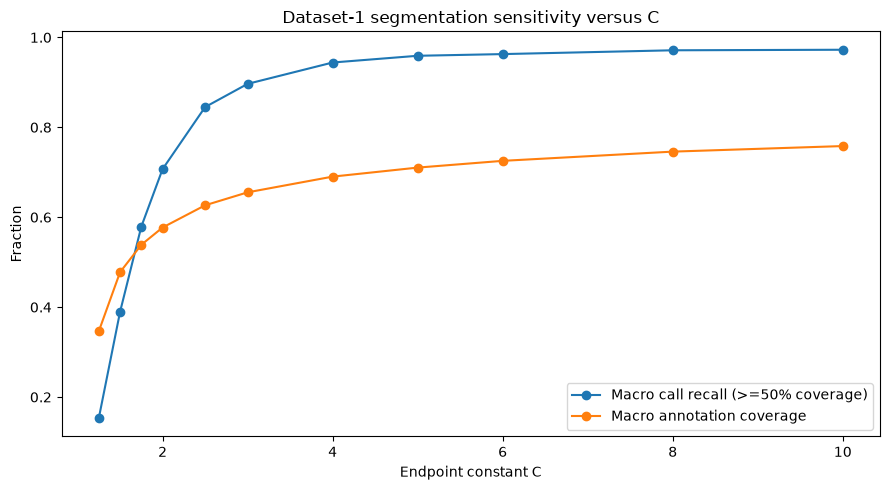

In [16]:
macro_grid_rows = []

for C, group in species_grid.groupby(
    "C",
    sort=True,
):

    macro_grid_rows.append({
        "C":
            float(C),
        "macro_call_recall_50":
            float(
                group[
                    "call_recall_50"
                ].mean()
            ),
        "macro_annotation_coverage":
            float(
                group[
                    "annotation_coverage"
                ].mean()
            ),
        "macro_candidate_burden_ratio":
            float(
                group[
                    "candidate_burden_ratio"
                ].mean()
            ),
    })

macro_grid = pd.DataFrame(
    macro_grid_rows
)

display(
    macro_grid.round(4)
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    macro_grid[
        "C"
    ],
    macro_grid[
        "macro_call_recall_50"
    ],
    marker="o",
    label="Macro call recall (>=50% coverage)",
)

ax.plot(
    macro_grid[
        "C"
    ],
    macro_grid[
        "macro_annotation_coverage"
    ],
    marker="o",
    label="Macro annotation coverage",
)

ax.set(
    title="Dataset-1 segmentation sensitivity versus C",
    xlabel="Endpoint constant C",
    ylabel="Fraction",
)

ax.legend()

plt.tight_layout()
plt.show()

## 15. Per-species sensitivity curves

The recall curve should generally rise as `C` makes the threshold more permissive. Candidate burden
usually rises with it.

Large discontinuities are worth inspecting because they often mean one recording has a very different
SNR distribution.

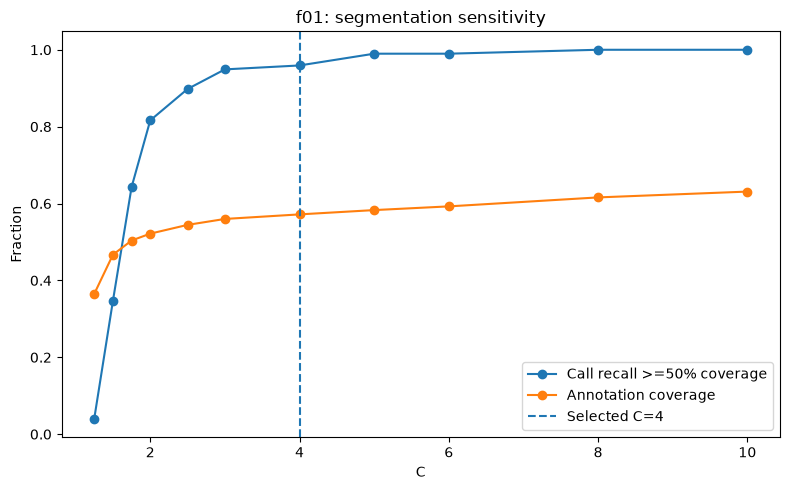

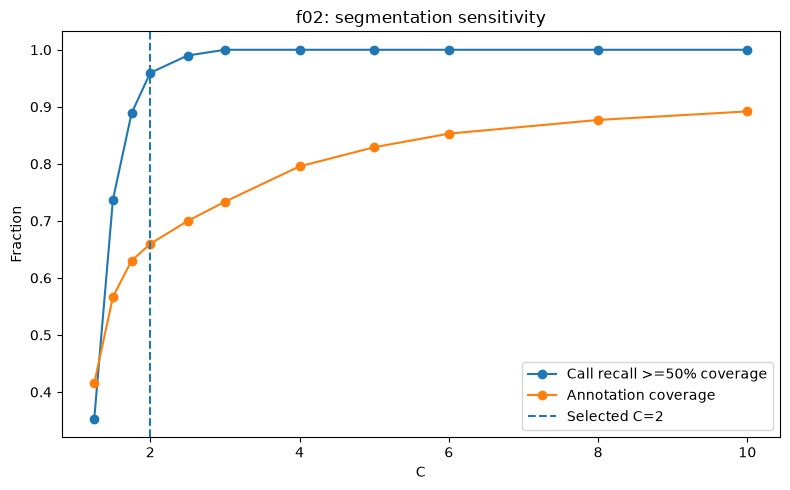

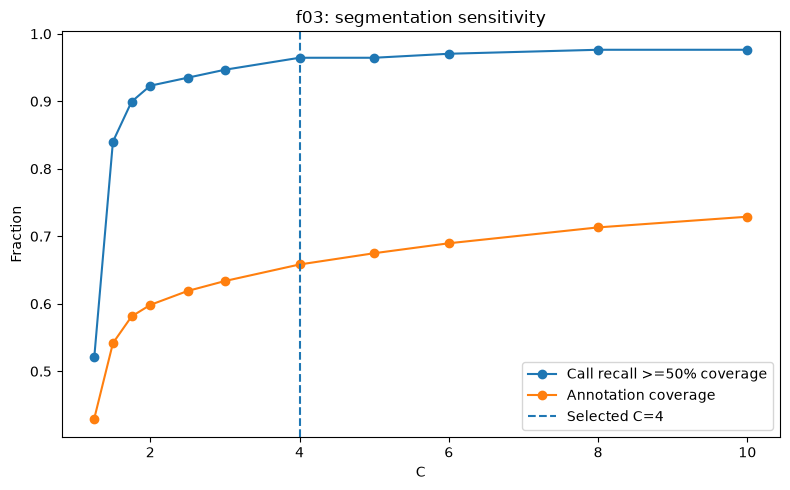

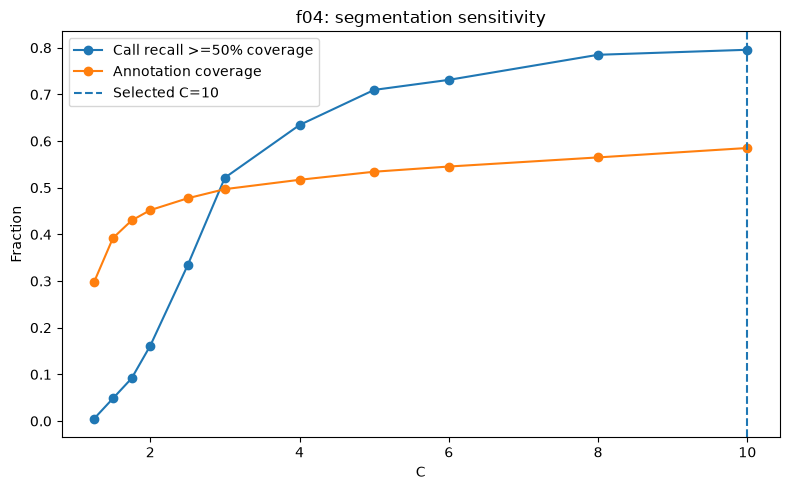

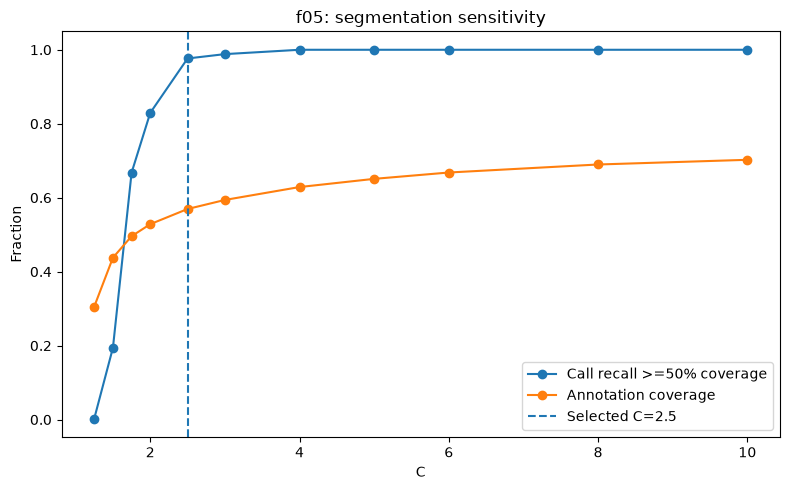

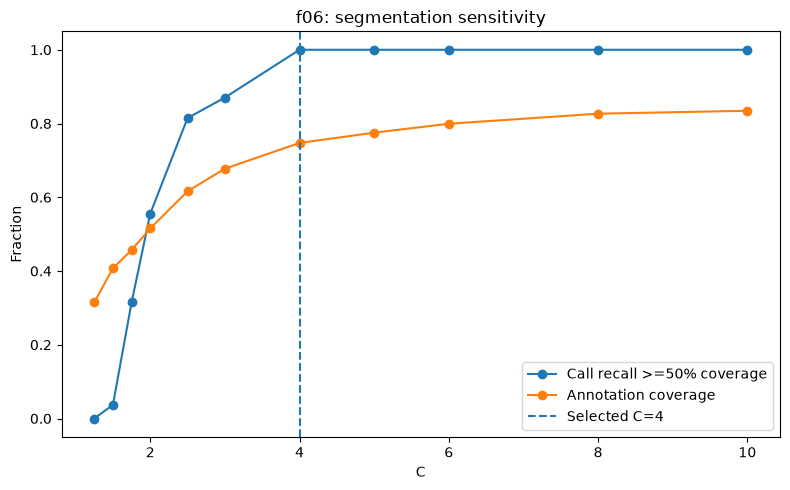

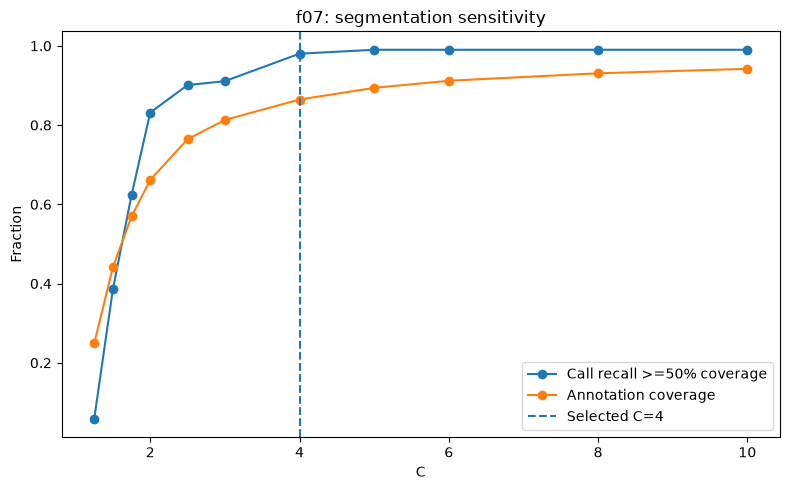

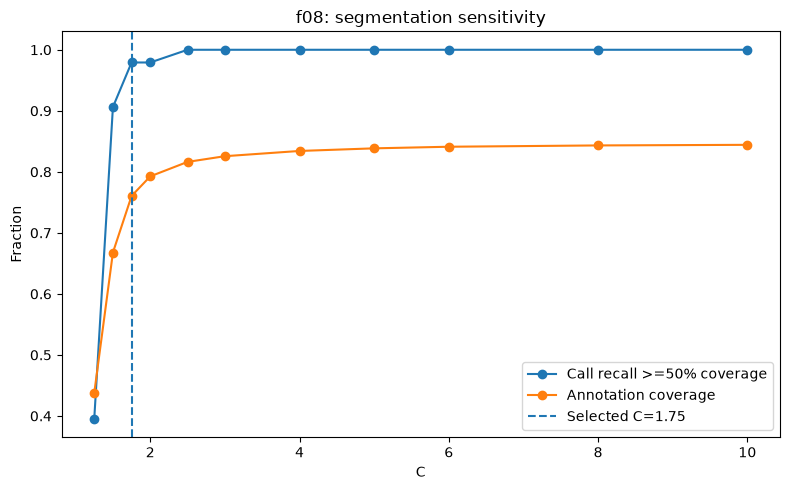

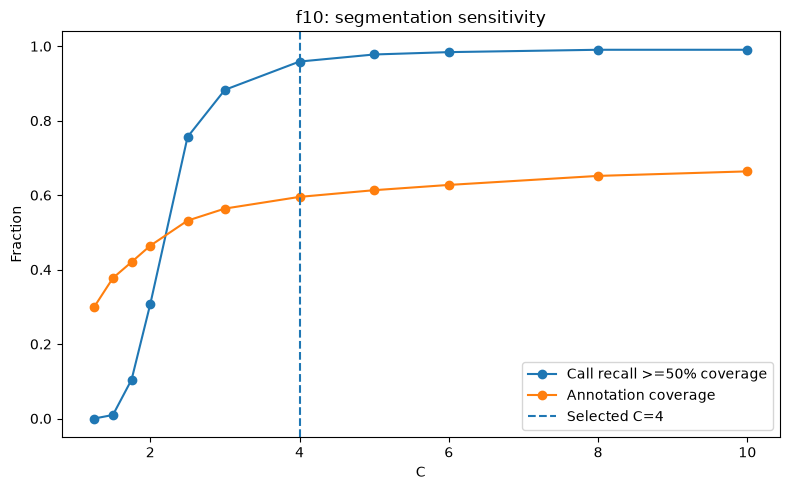

In [17]:
for code in USABLE_CODES:

    subset = (
        species_grid[
            species_grid[
                "code"
            ] == code
        ]
        .sort_values(
            "C"
        )
    )

    selected_C = float(
        C_BY_CODE[
            code
        ]
    )

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    ax.plot(
        subset[
            "C"
        ],
        subset[
            "call_recall_50"
        ],
        marker="o",
        label="Call recall >=50% coverage",
    )

    ax.plot(
        subset[
            "C"
        ],
        subset[
            "annotation_coverage"
        ],
        marker="o",
        label="Annotation coverage",
    )

    ax.axvline(
        selected_C,
        linestyle="--",
        label=f"Selected C={selected_C:g}",
    )

    ax.set(
        title=f"{code}: segmentation sensitivity",
        xlabel="C",
        ylabel="Fraction",
    )

    ax.legend()

    plt.tight_layout()
    plt.show()

## 16. Re-run the selected constants and save candidate intervals

The selected candidates are generated from the annotated Dataset-1 WAVs only.

These intervals are useful for:

- manual visual inspection;
- endpoint-error diagnostics;
- testing the frozen classifier on automatically segmented candidate calls later.

They are **not** pond detections.

In [18]:
selected_candidate_blocks = []
selected_call_metric_blocks = []
selected_recording_metric_rows = []

grouped = list(
    usable_calls.groupby(
        [
            "code",
            "recording_group",
            "resolved_wav",
        ],
        sort=True,
    )
)

for group_index, (
    (
        code,
        recording_group,
        resolved_wav,
    ),
    gt_group,
) in enumerate(
    grouped,
    start=1,
):

    C = float(
        C_BY_CODE[
            code
        ]
    )

    print(
        f"{group_index:>3}/{len(grouped)} | "
        f"{code} | C={C:g} | {Path(resolved_wav).name}"
    )

    prepared = (
        prepare_recording_frontend(
            resolved_wav,
            code,
        )
    )

    candidates = (
        candidates_from_prepared(
            prepared,
            C=C,
        )
    )

    sr = int(
        prepared[
            "sr"
        ]
    )

    summary, call_metrics = (
        evaluate_candidates(
            ground_truth=gt_group,
            candidates=candidates,
            sr=sr,
        )
    )

    if not candidates.empty:

        candidates[
            "recording_group"
        ] = recording_group

        candidates[
            "wav"
        ] = Path(
            resolved_wav
        ).name

        selected_candidate_blocks.append(
            candidates
        )

    call_metrics[
        "recording_group"
    ] = recording_group

    call_metrics[
        "selected_C"
    ] = C

    selected_call_metric_blocks.append(
        call_metrics
    )

    selected_recording_metric_rows.append({
        "code":
            code,
        "recording_group":
            recording_group,
        "wav":
            Path(
                resolved_wav
            ).name,
        "selected_C":
            C,
        **summary,
    })

selected_candidates = (
    pd.concat(
        selected_candidate_blocks,
        ignore_index=True,
    )
    if selected_candidate_blocks
    else pd.DataFrame()
)

selected_call_metrics = pd.concat(
    selected_call_metric_blocks,
    ignore_index=True,
)

selected_recording_metrics = pd.DataFrame(
    selected_recording_metric_rows
)

print(
    "Selected candidate intervals:",
    len(
        selected_candidates
    ),
)

display(
    selected_recording_metrics.head().round(4)
)

  1/66 | f01 | C=4 | 1101.WAV
  2/66 | f01 | C=4 | 1102.WAV
  3/66 | f01 | C=4 | 1103.WAV
  4/66 | f01 | C=4 | 1105.WAV
  5/66 | f01 | C=4 | 1106.WAV
  6/66 | f02 | C=2 | D-bifircus-D-parviceps-LS100120.WAV
  7/66 | f02 | C=2 | D-bifurcus-sc10743.wav
  8/66 | f02 | C=2 | Dbifurcus2.WAV
  9/66 | f02 | C=2 | Drhodopeplusbifurcus2_Daniel1.WAV
 10/66 | f02 | C=2 | LS100120.WAV
 11/66 | f02 | C=2 | LS100303 D. bifurcus sc38590mono.WAV
 12/66 | f02 | C=2 | LS100536.WAV
 13/66 | f02 | C=2 | LS100582.WAV
 14/66 | f02 | C=2 | LS100584.WAV
 15/66 | f02 | C=2 | LS100594.WAV
 16/66 | f03 | C=4 | Hcinerascens.WAV
 17/66 | f03 | C=4 | Hcinerascens2_Daniel.WAV
 18/66 | f03 | C=4 | Hcinerascens3.WAV
 19/66 | f03 | C=4 | LS100305_Daniel1.WAV
 20/66 | f03 | C=4 | LS100306.WAV
 21/66 | f03 | C=4 | LS100444 H. cinerascensmono.WAV
 22/66 | f03 | C=4 | LS100459 sc44991-92.WAV
 23/66 | f03 | C=4 | LS100732.WAV
 24/66 | f04 | C=10 | LS100307.WAV
 25/66 | f04 | C=10 | LS100308- Pristimantis conspicillatus.WAV


,code,recording_group,wav,selected_C,n_gt_calls,n_candidates,call_recall_any,call_recall_50,median_call_coverage,annotation_coverage,candidate_overlap_share,candidate_seconds,annotated_seconds_union,candidate_burden_ratio
0,f01,1101.wav,1101.WAV,4.0,21,52,1.0,1.0000,0.5909,0.5924,0.6504,8.38,9.20,0.9109
1,f01,1102.wav,1102.WAV,4.0,21,58,1.0,1.0000,0.5625,0.5734,0.5831,10.05,10.22,0.9834
2,f01,1103.wav,1103.WAV,4.0,18,50,1.0,1.0000,0.5833,0.5807,0.5005,9.49,8.18,1.1601
3,f01,1105.wav,1105.WAV,4.0,19,66,1.0,0.8421,0.5652,0.5648,0.4400,11.09,8.64,1.2836
4,f01,1106.wav,1106.WAV,4.0,19,47,1.0,0.9474,0.5417,0.5460,0.5936,7.80,8.48,0.9198


## 17. Calls near 30-second boundaries

Because the paper explicitly segments consecutive 30 s blocks, calls crossing a block boundary are a
special case.

They may legitimately be split into two candidates. The coverage-based evaluation above can still
credit both pieces.

In [19]:
boundary_rows = []

for row in usable_calls.itertuples(
    index=False
):

    sr = int(
        row.rate
    )

    block_samples = int(
        round(
            BLOCK_SECONDS
            * sr
        )
    )

    start_block = (
        int(
            row.start
        )
        // block_samples
    )

    end_block = (
        max(
            int(
                row.end
            )
            - 1,
            int(
                row.start
            ),
        )
        // block_samples
    )

    if start_block != end_block:

        boundary_rows.append({
            "call_id":
                row.call_id,
            "code":
                row.code,
            "wav":
                row.wav,
            "start_seconds":
                row.start
                / sr,
            "end_seconds":
                row.end
                / sr,
            "start_block":
                start_block,
            "end_block":
                end_block,
        })

boundary_calls = pd.DataFrame(
    boundary_rows
)

print(
    "Annotated calls crossing a 30-s boundary:",
    len(
        boundary_calls
    ),
)

if not boundary_calls.empty:
    display(
        boundary_calls.head(
            30
        )
    )

Annotated calls crossing a 30-s boundary: 21


,call_id,code,wav,start_seconds,end_seconds,start_block,end_block
0,call_0046,f01,1103.WAV,29.750930,30.230930,0,1
1,call_0075,f01,1105.WAV,149.592857,150.052857,4,5
2,call_0205,f03,Hcinerascens.WAV,29.889688,30.549688,0,1
3,call_0239,f03,Hcinerascens3.WAV,29.610063,30.130063,0,1
4,call_0344,f03,LS100459 sc44991-92.WAV,89.954853,90.454853,2,3
5,call_0414,f04,LS100309sc37073.WAV,149.722925,150.122925,4,5
6,call_0427,f04,LS100313- Pristimantis conspicillatus.WAV,209.848685,210.248685,6,7
7,call_0519,f04,LS100326SC37214 mn_Daniel.wav,149.646327,150.086327,4,5
8,call_0526,f04,LS100329sc37220 mn conspicillatus_Daniel2.wav,29.721497,30.101497,0,1
9,call_0729,f05,Leptodactylus discodactylus.WAV,419.858708,420.178708,13,14


## 18. Worst-covered annotated calls

This is the first table to inspect if any species fails the recall target.

In [20]:
worst_calls = (
    selected_call_metrics
    .sort_values(
        [
            "coverage",
            "code",
            "call_id",
        ]
    )
    .reset_index(drop=True)
)

display(
    worst_calls.head(
        50
    ).round(4)
)

,call_id,code,wav,coverage,any_overlap,covered_50pct,recording_group,selected_C
0,call_1301,f10,Epetersi_Daniel1.WAV,0.0000,False,False,epetersi_daniel1.wav,4.00
1,call_1113,f08,LS100169 R. margaritifer sc28485 Limoncocha.WAV,0.1333,True,False,ls100169 r. margaritifer sc28485 limoncocha.wav,1.75
2,call_1302,f10,Epetersi_Daniel1.WAV,0.1818,True,False,epetersi_daniel1.wav,4.00
3,call_1303,f10,Epetersi_Daniel1.WAV,0.1905,True,False,epetersi_daniel1.wav,4.00
4,call_0962,f07,"D.triangulum, H.geographicus, H.lanciformis.WAV",0.2955,True,False,"d.triangulum, h.geographicus, h.lanciformis.wav",4.00
5,call_1114,f08,LS100169 R. margaritifer sc28485 Limoncocha.WAV,0.2969,True,False,ls100169 r. margaritifer sc28485 limoncocha.wav,1.75
6,call_0202,f03,Hcinerascens.WAV,0.3684,True,False,hcinerascens.wav,4.00
7,call_0253,f03,LS100305_Daniel1.WAV,0.3684,True,False,ls100305_daniel1.wav,4.00
8,call_0199,f03,Hcinerascens.WAV,0.3750,True,False,hcinerascens.wav,4.00
9,call_0203,f03,Hcinerascens.WAV,0.3750,True,False,hcinerascens.wav,4.00


## 19. Visual inspection of one labelled recording

The plot overlays:

- manual target-call intervals;
- candidate intervals produced with the selected `C`.

The waveform shown is the **original unfiltered audio**, because candidate timestamps ultimately refer
back to that signal.

C:\Users\sofia\AppData\Local\Temp\ipykernel_6576\3137478392.py:127: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\sofia\Projects\PUCE\frog-presence-replication\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


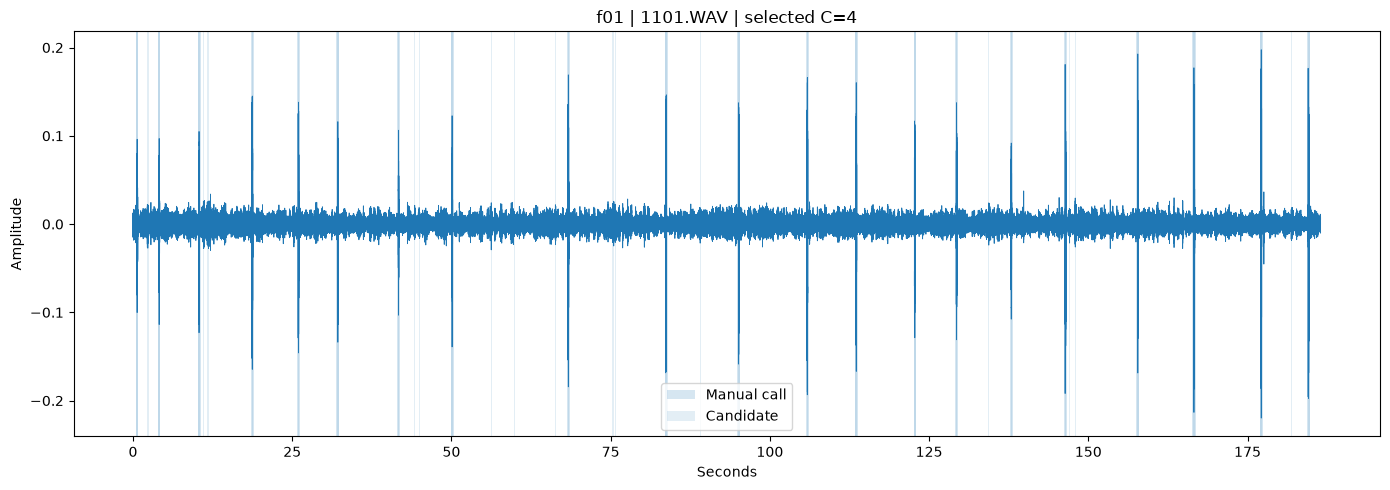

In [21]:
EXAMPLE_CODE = USABLE_CODES[0]

example_record = (
    recording_inventory[
        recording_inventory[
            "code"
        ] == EXAMPLE_CODE
    ]
    .iloc[0]
)

example_wav = Path(
    example_record[
        "resolved_wav"
    ]
)

example_group = str(
    example_record[
        "recording_group"
    ]
)

example_audio, example_sr = (
    read_full_wav(
        example_wav
    )
)

example_gt = (
    usable_calls[
        (
            usable_calls[
                "code"
            ] == EXAMPLE_CODE
        )
        & (
            usable_calls[
                "recording_group"
            ] == example_group
        )
    ]
)

example_candidates = (
    selected_candidates[
        (
            selected_candidates[
                "code"
            ] == EXAMPLE_CODE
        )
        & (
            selected_candidates[
                "recording_group"
            ] == example_group
        )
    ]
)

time = (
    np.arange(
        len(
            example_audio
        )
    )
    / example_sr
)

fig, ax = plt.subplots(
    figsize=(
        14,
        5,
    )
)

ax.plot(
    time,
    example_audio,
    linewidth=0.6,
)

for i, row in enumerate(
    example_gt.itertuples(
        index=False
    )
):
    ax.axvspan(
        row.start
        / example_sr,
        row.end
        / example_sr,
        alpha=0.18,
        label=(
            "Manual call"
            if i == 0
            else None
        ),
    )

for i, row in enumerate(
    example_candidates.itertuples(
        index=False
    )
):
    ax.axvspan(
        row.start_seconds,
        row.end_seconds,
        alpha=0.12,
        label=(
            "Candidate"
            if i == 0
            else None
        ),
    )

ax.set(
    title=(
        f"{EXAMPLE_CODE} | {example_wav.name} | "
        f"selected C={C_BY_CODE[EXAMPLE_CODE]:g}"
    ),
    xlabel="Seconds",
    ylabel="Amplitude",
)

ax.legend()

plt.tight_layout()
plt.show()

## 20. Export segmentation-development configuration

The selected constants are **development values learned from Dataset 1**.

They should be carried into the later field experiment without retuning on pond labels unless a
separate, explicitly documented field-development set is introduced.

In [22]:
selected_config = {
    "source_notebook":
        "08_candidate_call_segmentation",
    "scope":
        "Dataset 1 labelled call segmentation development",
    "field_audio_used":
        False,
    "paper_frontend": {
        "block_seconds":
            BLOCK_SECONDS,
        "ste_frame_seconds":
            STE_FRAME_SECONDS,
        "ste_overlap":
            0.0,
        "moving_average_length":
            STE_MA_LENGTH,
        "endpoint_run_length":
            ENDPOINT_RUN,
        "species_frequency_bands_hz":
            {
                code: [
                    float(
                        SEGMENTATION_BANDS_HZ[
                            code
                        ][0]
                    ),
                    float(
                        SEGMENTATION_BANDS_HZ[
                            code
                        ][1]
                    ),
                ]
                for code
                in USABLE_CODES
            },
    },
    "replication_decisions": {
        "fir_numtaps":
            FIR_NUMTAPS,
        "filter_alignment":
            "fftconvolve mode=same",
        "moving_average_boundary_mode":
            "numpy convolve mode=same",
        "threshold_interpretation":
            (
                "mean(STE_dB) + "
                "(max(STE_dB)-mean(STE_dB))/C"
            ),
        "paper_C_reported":
            False,
    },
    "selection": {
        "call_coverage_target":
            CALL_COVERAGE_TARGET,
        "target_call_recall":
            TARGET_CALL_RECALL,
        "C_grid":
            list(
                C_GRID
            ),
        "C_by_code":
            C_BY_CODE,
    },
    "limitations": [
        (
            "C values are tuned on Dataset 1 and are not independent "
            "field-performance estimates"
        ),
        (
            "non-overlapping candidates cannot automatically be called "
            "biological false positives because annotation scope is target calls"
        ),
        (
            "paper does not report FIR order, C, or exact boundary handling"
        ),
        (
            "f09 is not part of the frozen deployable detector"
        ),
    ],
}

CONFIG_PATH = (
    RESULTS_DIR
    / "selected_segmentation_configuration.json"
)

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        selected_config,
        f,
        indent=2,
    )

print(
    json.dumps(
        selected_config,
        indent=2,
    )
)

{
  "source_notebook": "08_candidate_call_segmentation",
  "scope": "Dataset 1 labelled call segmentation development",
  "field_audio_used": false,
  "paper_frontend": {
    "block_seconds": 30.0,
    "ste_frame_seconds": 0.01,
    "ste_overlap": 0.0,
    "moving_average_length": 12,
    "endpoint_run_length": 3,
    "species_frequency_bands_hz": {
      "f01": [
        1660.0,
        3100.0
      ],
      "f02": [
        2300.0,
        3390.0
      ],
      "f03": [
        1300.0,
        1530.0
      ],
      "f04": [
        1630.0,
        3900.0
      ],
      "f05": [
        1680.0,
        3260.0
      ],
      "f06": [
        1000.0,
        2500.0
      ],
      "f07": [
        500.0,
        2720.0
      ],
      "f08": [
        800.0,
        1700.0
      ],
      "f10": [
        430.0,
        3140.0
      ]
    }
  },
  "replication_decisions": {
    "fir_numtaps": 513,
    "filter_alignment": "fftconvolve mode=same",
    "moving_average_boundary_mode": "numpy c

## 21. Save result tables

In [23]:
species_grid.to_csv(
    RESULTS_DIR
    / "segmentation_grid_by_species.csv",
    index=False,
)

selected_segmentation.to_csv(
    RESULTS_DIR
    / "selected_segmentation_metrics.csv",
    index=False,
)

selected_vs_c2.to_csv(
    RESULTS_DIR
    / "selected_vs_provisional_C2.csv",
    index=False,
)

macro_grid.to_csv(
    RESULTS_DIR
    / "segmentation_macro_grid.csv",
    index=False,
)

selected_candidates.to_csv(
    RESULTS_DIR
    / "selected_dataset1_candidates.csv",
    index=False,
)

selected_call_metrics.to_csv(
    RESULTS_DIR
    / "selected_dataset1_call_coverage.csv",
    index=False,
)

selected_recording_metrics.to_csv(
    RESULTS_DIR
    / "selected_dataset1_recording_metrics.csv",
    index=False,
)

boundary_calls.to_csv(
    RESULTS_DIR
    / "calls_crossing_30s_boundaries.csv",
    index=False,
)

print(
    "Saved segmentation outputs:"
)

for path in sorted(
    RESULTS_DIR.iterdir()
):
    print(
        f"  {path.name:<46} "
        f"{path.stat().st_size / 1e6:>8.3f} MB"
    )

Saved segmentation outputs:
  calls_crossing_30s_boundaries.csv                 0.002 MB
  segmentation_grid_by_species.csv                  0.013 MB
  segmentation_grid_metrics.csv                     0.213 MB
  segmentation_macro_grid.csv                       0.001 MB
  selected_dataset1_call_coverage.csv               0.154 MB
  selected_dataset1_candidates.csv                  2.227 MB
  selected_dataset1_recording_metrics.csv           0.011 MB
  selected_segmentation_configuration.json          0.002 MB
  selected_segmentation_metrics.csv                 0.002 MB
  selected_vs_provisional_C2.csv                    0.001 MB


## 22. Interpretation and next step

After execution, inspect these outputs first:

1. `selected_segmentation`
2. `selected_vs_c2`
3. `macro_grid`
4. `worst_calls`
5. the example waveform plot

### Decision logic

If most species achieve high annotated-call recall without an absurd candidate-duration burden, the
front end is usable for the next stage.

If one or more species remain poor even at high `C`, do **not** compensate by changing the frozen GMM
detector. The problem is upstream and should be diagnosed as:

- frequency-band mismatch;
- energy-threshold behavior;
- moving-average merging;
- unusually low-SNR recordings;
- 30-second boundary effects.

### Next notebook

Only after this segmentation-development notebook is accepted should we build the field inference stage:

`09_field_presence_absence.ipynb`

That notebook will finally combine:

**pond WAV → 30 s segmentation → original unfiltered candidate → 20 PLP-RASTA → frozen GMMs →
final LLR thresholds → presence/absence.**

The segmentation constants selected here should enter that notebook as frozen development parameters,
not as knobs to be adjusted until the pond output looks pleasing.